In [6]:
df.describe(include="all").T 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,549.0,NaN,NaN,NaN,274.0,158.626921,0.0,137.0,274.0,411.0,548.0
price,548.0,NaN,NaN,NaN,4779408.649635,1896038.235454,1750000.0,3456250.0,4340000.0,5748750.0,13300000.0
area,549,284,"""6000""",24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bedrooms,546.0,NaN,NaN,NaN,2.967033,0.736227,1.0,2.25,3.0,3.0,6.0
bathrooms,546.0,NaN,NaN,NaN,1.291209,0.515267,1.0,1.0,1.0,2.0,4.0
stories,549.0,NaN,NaN,NaN,1.810565,0.87159,1.0,1.0,2.0,2.0,4.0
mainroad,547,2,yes,471,NaN,NaN,NaN,NaN,NaN,NaN,NaN
guestroom,549,2,no,452,NaN,NaN,NaN,NaN,NaN,NaN,NaN
basement,549,2,no,356,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hotwaterheating,549,2,no,524,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
print(df.describe())

       Unnamed: 0         price    bedrooms   bathrooms     stories  \
count  549.000000  5.480000e+02  546.000000  546.000000  549.000000   
mean   274.000000  4.779409e+06    2.967033    1.291209    1.810565   
std    158.626921  1.896038e+06    0.736227    0.515267    0.871590   
min      0.000000  1.750000e+06    1.000000    1.000000    1.000000   
25%    137.000000  3.456250e+06    2.250000    1.000000    1.000000   
50%    274.000000  4.340000e+06    3.000000    1.000000    2.000000   
75%    411.000000  5.748750e+06    3.000000    2.000000    2.000000   
max    548.000000  1.330000e+07    6.000000    4.000000    4.000000   

          parking  price_annuel  
count  549.000000  5.480000e+02  
mean     0.697632  5.735290e+07  
std      0.866875  2.275246e+07  
min      0.000000  2.100000e+07  
25%      0.000000  4.147500e+07  
50%      0.000000  5.208000e+07  
75%      1.000000  6.898500e+07  
max      3.000000  1.596000e+08  


### Question 9 : Normalisation

**Quels attributs faut-il normaliser ?**
Les attributs numériques : `price`, `area`, `bedrooms`, `bathrooms`, `stories` et `parking`.
Leurs échelles sont très différentes (`price` de l'ordre de 10⁶ à 10⁷, `area` de 10³, alors que
`bedrooms`, `bathrooms`, `stories` et `parking` vont de 0 à 6). Les attributs catégoriels ne
sont pas normalisés : une fois encodés en 0/1, ils sont déjà sur une échelle comparable.

**Quelle méthode ?**
Le **Z-score** (standardisation) : z = (x − moyenne) / écart-type.
Après transformation, chaque attribut a une moyenne ≈ 0 et un écart-type ≈ 1
(vérifié : moyennes ~10⁻¹⁶, écarts-types = 1,0009).

**Pourquoi le Z-score plutôt que le Min-Max ?**
Nous avons conservé des outliers (Q8). Avec le Min-Max, ces valeurs extrêmes fixent le min et le
max, ce qui écraserait la majorité des données dans un intervalle très étroit. Le Z-score est
moins sensible à ce problème.

**Quel est son objectif ?**
Mettre tous les attributs sur la même échelle, pour qu'un attribut aux grandes valeurs (`price`,
`area`) ne domine pas les autres dans les algorithmes basés sur des distances ou des gradients
(k-means, kNN, régression, réseaux de neurones, etc.).

In [ ]:
# Z-score : moyenne ~ 0 et ecart-type ~ 1. Conseille quand il y a des outliers

from sklearn.preprocessing import StandardScaler

df_z = df.copy()
df_z[num_cols] = StandardScaler().fit_transform(df[num_cols])
print(df_z[num_cols].describe().T[["mean", "std", "min", "max"]])

                   mean       std       min       max
price      5.205441e-17  1.000917 -1.602811  4.523661
area       1.301360e-16  1.000917 -1.614673  5.083365
bedrooms  -1.821904e-16  1.000917 -2.674225  4.123385
bathrooms -2.342449e-16  1.000917 -0.565679  5.261879
stories    0.000000e+00  1.000917 -0.929450  2.514982
parking    2.602721e-17  1.000917 -0.806110  2.659527


### Question 8 : Box plots et valeurs aberrantes

**Résultats (méthode IQR, 546 lignes)**

| Attribut | Outliers | %     | Borne haute |
|----------|----------|-------|-------------|
| price    | 16       | 2,9 % | ≈ 9 191 875 |
| area     | 12       | 2,2 % | 10 500      |
| bedrooms | 14       | 2,6 % | ≈ 4         |
| bathrooms| 2        | 0,4 % | 3,5         |
| stories  | 42       | 7,7 % | 3,5         |
| parking  | 13       | 2,4 % | 2,5         |

Pour `price` et `area`, les bornes basses sont négatives : il n'y a donc aucun outlier en bas.

**Qu'est-ce qu'un outlier ?**
Une valeur qui s'écarte fortement du reste des données. Avec la règle de l'IQR, c'est une valeur
située au-delà de Q3 + 1,5 × IQR ou en dessous de Q1 − 1,5 × IQR. Sur le box plot, ce sont les
points isolés au-delà des moustaches.

**Est-ce une erreur ou une valeur réelle ?**
Ce sont des **valeurs réelles**, pas des erreurs :
- `price` (16) et `area` (12) : ce sont de grandes maisons de luxe, chères et très spacieuses.
  Aucune valeur négative, nulle ou impossible, et ces deux attributs sont liés (corrélation 0,55).
- `bedrooms`, `bathrooms`, `stories`, `parking` : ce sont des comptages à très peu de valeurs
  distinctes. Leur IQR est très étroit, donc la règle de l'IQR classe comme « outliers » des
  valeurs rares mais plausibles (maisons à 4 étages, 3 places de parking, 5 ou 6 chambres).
  C'est surtout visible pour `stories` (42 outliers, soit 7,7 %) : la règle de l'IQR est peu
  adaptée aux variables discrètes.

**Quel traitement faut-il appliquer ?**
On ne supprime pas les outliers : ils représentent de vraies maisons, et en retirer 3 % à
8 % des lignes ferait perdre de l'information. On les conserve et on applique une
normalisation adaptée à leur présence (Z-score).

In [37]:
# compter les outliers (méthode IQR) : outlier si valeur < Q1 - 1.5*IQR ou valeur > Q3 + 1.5*IQR
for c in num_cols:
    Q1, Q3 = df[c].quantile(0.25), df[c].quantile(0.75)
    IQR = Q3 - Q1
    bas, haut = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n = ((df[c] < bas) | (df[c] > haut)).sum()
    print(f"{c}: {n} outliers (bornes : {bas:.0f} a {haut:.0f})")

price: 16 outliers (bornes : -13125 a 9191875)
area: 12 outliers (bornes : -540 a 10500)
bedrooms: 14 outliers (bornes : 1 a 4)
bathrooms: 2 outliers (bornes : -0 a 4)
stories: 42 outliers (bornes : -0 a 4)
parking: 13 outliers (bornes : -2 a 2)


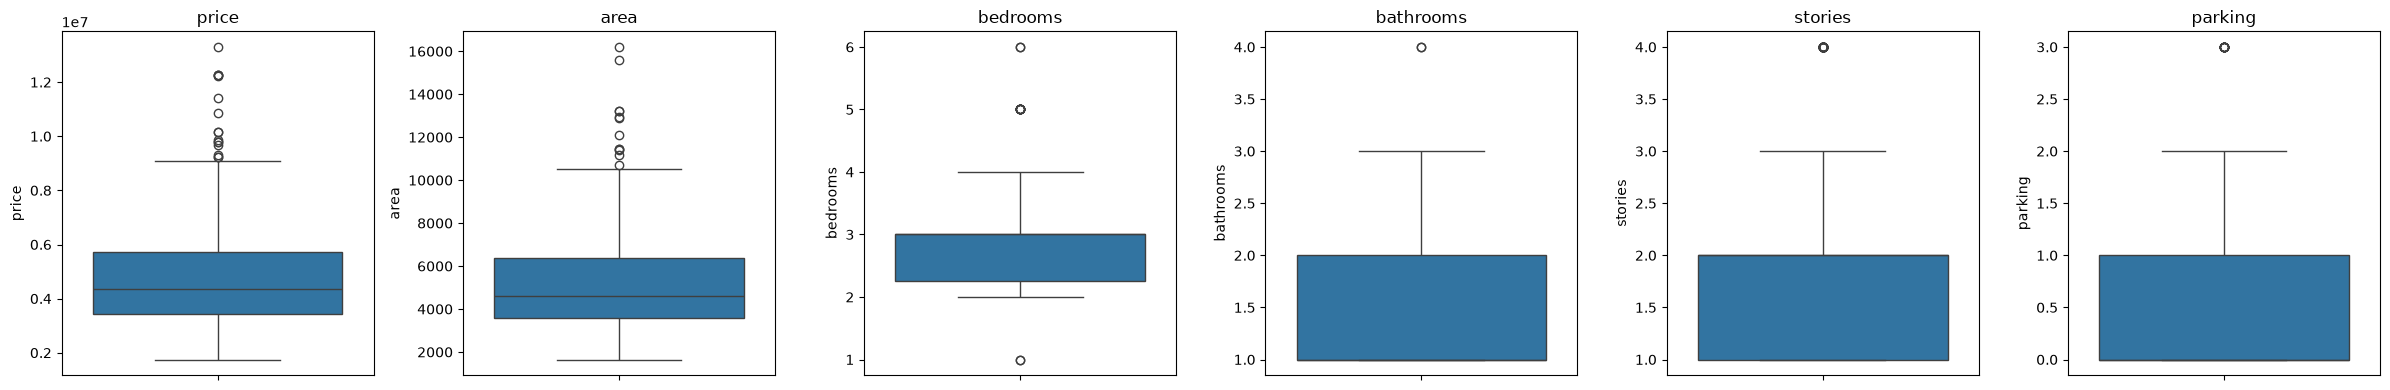

In [ ]:
# Un box plot par attribut numerique 
fig, axes = plt.subplots(1, len(num_cols), figsize=(4 * len(num_cols), 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=df[c], ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

In [35]:
# Les 5 valeurs de chaque attribut numerique : min, Q1, mediane, Q3, max
cinq_valeurs = df[num_cols].describe().T[["min", "25%", "50%", "75%", "max"]]
cinq_valeurs.columns = ["min", "Q1", "mediane", "Q3", "max"]
print(cinq_valeurs)


                 min          Q1    mediane         Q3         max
price      1750000.0  3438750.00  4340000.0  5740000.0  13300000.0
area          1650.0     3600.00     4600.0     6360.0     16200.0
bedrooms         1.0        2.25        3.0        3.0         6.0
bathrooms        1.0        1.00        1.0        2.0         4.0
stories          1.0        1.00        2.0        2.0         4.0
parking          0.0        0.00        0.0        1.0         3.0


### Question 7 : Doublons après traitement

Avant suppression, `duplicated().sum()` renvoyait 3: l'imputation des valeurs manquantes
n'a pas créé de nouveaux doublons, les 3 paires détectées étaient déjà identiques sur
tous les attributs.

Après `drop_duplicates()` (on conserve la première occurrence), il reste 0 doublon et le
dataset passe de 549 à 546 lignes.

In [ ]:
# Suppression des doublons (on garde la premiere occurrence)
df = df.drop_duplicates()
print(df.duplicated().sum())  


0


In [32]:
# Verification des doublons apres le traitement des valeurs manquantes
print(df.duplicated().sum())

3


### Question 6 : Valeurs manquantes

5 attributs contiennent des valeurs manquantes : `price` (1), `bedrooms` (3),
`bathrooms` (3), `mainroad` (2) et `furnishingstatus` (3), soit très peu par rapport aux
549 lignes.

**Méthode choisie et justification :**

- **Attributs numériques (`price`, `bedrooms`, `bathrooms`) : imputation par la médiane.**
  La médiane est robuste aux valeurs extrêmes. `price` est asymétrique à droite, donc la
  moyenne serait tirée vers le haut par les outliers.
- **Attributs catégoriels (`mainroad`, `furnishingstatus`) : imputation par le mode**
  (valeur la plus fréquente : `yes` et `semi-furnished`), car on ne peut pas calculer de
  moyenne ni de médiane sur du texte.
- On n'a pas supprimé les lignes : il y en a très peu et on perdrait des données utiles.

Après traitement, `isna().sum()` vaut 0 pour tous les attributs. `bedrooms` et `bathrooms`
sont reconvertis en entiers.

In [31]:
# Verification : plus aucun manquant
print(df.isna().sum())
print(df.dtypes)

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64
price               float64
area                  int64
bedrooms              int64
bathrooms             int64
stories               int64
mainroad                str
guestroom               str
basement                str
hotwaterheating         str
airconditioning         str
parking               int64
prefarea                str
furnishingstatus        str
dtype: object


In [30]:
# bedrooms et bathrooms etaient en float64 uniquement a cause des NaN.
# Plus aucun manquant : on les remet en entier (ce sont des comptages).
df["bedrooms"] = df["bedrooms"].astype(int)
df["bathrooms"] = df["bathrooms"].astype(int)

In [ ]:
# Imputation des attributs categoriels par le mode (valeur la plus frequente), car la mediane n'a pas de sens sur du texte.
# mainroad -> "yes" (471 sur 547), furnishingstatus -> "semi-furnished" (228).
for c in ["mainroad", "furnishingstatus"]:
    df[c] = df[c].fillna(df[c].mode()[0])

In [ ]:
# Imputation des attributs numeriques par la mediane (robuste aux outliers).
# price est asymetrique a droite : la moyenne serait tiree vers le haut par les valeurs extremes.
# bedrooms et bathrooms sont des comptages : la mediane donne une valeur entiere realiste.
for c in ["price", "bedrooms", "bathrooms"]:
    df[c] = df[c].fillna(df[c].median())

In [25]:
print(df.isna().sum()) # nombre de manquants par attribut

price               1
area                0
bedrooms            3
bathrooms           3
stories             0
mainroad            2
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    3
dtype: int64


### Question 5 : Attributs catégoriels

**Que remarquons-nous ?**

- Le dataset contient 7 attributs catégoriels : `mainroad`, `guestroom`, `basement`,
  `hotwaterheating`, `airconditioning`, `prefarea` (binaires) et `furnishingstatus`
  (3 modalités attendues : furnished, semi-furnished, unfurnished).
- Les attributs binaires sont déséquilibrés : par exemple `mainroad` (471 yes / 76 no)
  et `guestroom` (452 no / 97 yes).
- `mainroad` et `furnishingstatus` contiennent des valeurs manquantes.
- `furnishingstatus` contient une erreur de saisie** : la valeur `FUrnished` (2 lignes) est
  comptée comme une modalité différente de `furnished` à cause de la casse.

**Faut-il corriger certaines valeurs ?**

Oui : on corrige `FUrnished` en `furnished` avec `str.lower()`, pour que chaque modalité soit
représentée une seule fois. Sans cette correction, l'encodage one-hot créerait une colonne
inutile.

In [42]:
df["furnishingstatus"] = df["furnishingstatus"].str.lower()
print(df["furnishingstatus"].value_counts(dropna=False))

furnishingstatus
semi-furnished    230
unfurnished       178
furnished         138
Name: count, dtype: int64


In [40]:
# furnishingstatus seul : la sortie precedente etait tronquee
print(df["furnishingstatus"].value_counts(dropna=False))

furnishingstatus
semi-furnished    230
unfurnished       178
furnished         138
Name: count, dtype: int64


In [39]:
# Valeurs uniques et frequences de chaque attribut categoriel.
for c in cat_cols:
    print(c, "-> valeurs uniques :", df[c].unique())
    print(df[c].value_counts())
    print()

mainroad -> valeurs uniques : <StringArray>
['yes', 'no']
Length: 2, dtype: str
mainroad
yes    470
no      76
Name: count, dtype: int64

guestroom -> valeurs uniques : <StringArray>
['no', 'yes']
Length: 2, dtype: str
guestroom
no     449
yes     97
Name: count, dtype: int64

basement -> valeurs uniques : <StringArray>
['no', 'yes']
Length: 2, dtype: str
basement
no     355
yes    191
Name: count, dtype: int64

hotwaterheating -> valeurs uniques : <StringArray>
['no', 'yes']
Length: 2, dtype: str
hotwaterheating
no     521
yes     25
Name: count, dtype: int64

airconditioning -> valeurs uniques : <StringArray>
['yes', 'no']
Length: 2, dtype: str
airconditioning
no     373
yes    173
Name: count, dtype: int64

prefarea -> valeurs uniques : <StringArray>
['yes', 'no']
Length: 2, dtype: str
prefarea
no     418
yes    128
Name: count, dtype: int64

furnishingstatus -> valeurs uniques : <StringArray>
['furnished', 'semi-furnished', 'unfurnished']
Length: 3, dtype: str
furnishingstatus
semi

In [20]:
# Liste des attributs categoriels 
cat_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
print("Attributs categoriels :", cat_cols)

Attributs categoriels : ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']


In [19]:
# Affichage des lignes en double (keep=False montre toutes les copies, originale comprise)
print(df[df.duplicated(keep=False)].sort_values(by=list(df.columns)))

         price   area  bedrooms  bathrooms  stories mainroad guestroom  \
312  4098500.0   3600       3.0        1.0        1      yes        no   
548  4098500.0   3600       3.0        1.0        1      yes        no   
300  4200000.0   4079       3.0        1.0        3      yes        no   
547  4200000.0   4079       3.0        1.0        3      yes        no   
10   9800000.0  13200       3.0        1.0        2      yes        no   
545  9800000.0  13200       3.0        1.0        2      yes        no   

    basement hotwaterheating airconditioning  parking prefarea  \
312      yes              no             yes        0      yes   
548      yes              no             yes        0      yes   
300       no              no              no        0       no   
547       no              no              no        0       no   
10       yes              no             yes        2      yes   
545      yes              no             yes        2      yes   

    furnishingstat

### Question 4 : Lignes en double

**Que remarquons-nous ?**

Le dataset contient 3 lignes dupliquées. En les affichant avec `keep=False`, on voit
3 paires de lignes strictement identiques sur tous les attributs :

1.
| Ligne originale : 10
| Copie : 545 
| price : 9 800 000 
| area :13 200  

2.
| Ligne originale : 300
| Copie : 547
| price : 4 200 000
| area :4 079

3.
| Ligne originale : 312
| Copie : 548
| price : 4 098 500 
| area : 3600


Les copies (545, 547, 548) se trouvent toutes à la fin du fichier, ce qui indique
qu'elles ont été ajoutées par erreur (copier-coller ou erreur de collecte), et non pas
qu'il s'agit de maisons réellement distinctes.


In [18]:
print(df.duplicated().sum()) # nombre de lignes dupliquees

3


In [17]:
# Mise a jour de la liste des attributs numeriques apres suppression de price_annuel.
num_cols = ["price", "area", "bedrooms", "bathrooms", "stories", "parking"]

In [ ]:
df = df.drop(columns=["price_annuel"])

In [ ]:
# Lignes ou price est manquant mais price_annuel est connu pour recuperer price exactement.
print(df[df["price"].isna() & df["price_annuel"].notna()][["price", "price_annuel"]])

Empty DataFrame
Columns: [price, price_annuel]
Index: []


                 price      area  bedrooms  bathrooms   stories   parking  \
price         1.000000  0.548397  0.365744   0.533472  0.428570  0.396435   
area          0.548397  1.000000  0.153396   0.198416  0.091368  0.364238   
bedrooms      0.365744  0.153396  1.000000   0.378440  0.409860  0.148116   
bathrooms     0.533472  0.198416  0.378440   1.000000  0.338452  0.195900   
stories       0.428570  0.091368  0.409860   0.338452  1.000000  0.056887   
parking       0.396435  0.364238  0.148116   0.195900  0.056887  1.000000   
price_annuel  1.000000  0.548397  0.365744   0.533472  0.428570  0.396435   

              price_annuel  
price             1.000000  
area              0.548397  
bedrooms          0.365744  
bathrooms         0.533472  
stories           0.428570  
parking           0.396435  
price_annuel      1.000000  


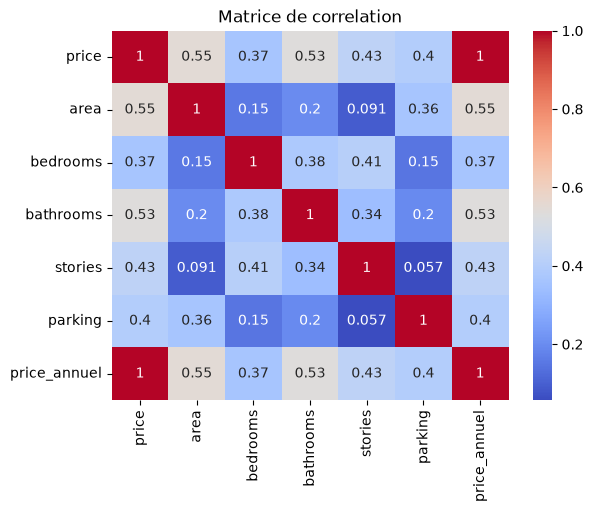

In [14]:
# Matrice de correlation
corr = df.select_dtypes(include=[np.number]).corr()
print(corr)

# heatmap annotee : proche de +1 / -1 = forte correlation
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Matrice de correlation")
plt.show()

### Question 3 : Matrice de corrélation

**Que remarquons-nous ?**

- `price` et `price_annuel` ont une corrélation de 1 : ils sont parfaitement corrélés. Les deux attributs contiennent exactement la même information.
- `price` est positivement corrélé avec `area` (0.55) et `bathrooms` (0.53), puis `stories`
  (0.43), `parking` (0.40) et `bedrooms` (0.37) : ce sont des corrélations moyennes.
- Entre les autres attributs, les corrélations restent faibles à moyennes (maximum 0.41 entre
  `bedrooms` et `stories`) : il n'y a pas d'autre redondance.

**Faut-il supprimer certains attributs ?**

Oui, il faut supprimer `price_annuel`. Il est redondant avec `price` (corrélation = 1). Les autres attributs sont conservés.

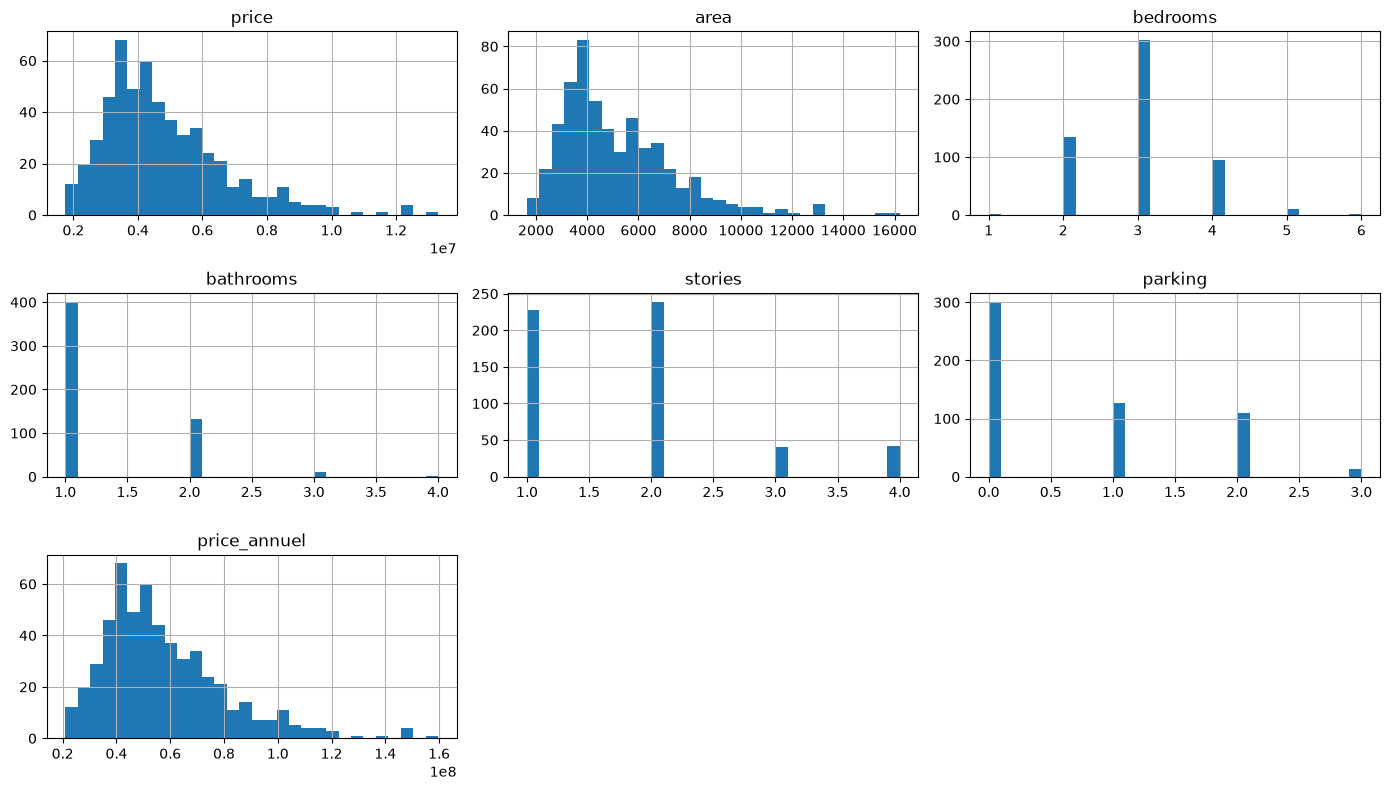

In [12]:
# Histograms.
df[num_cols].hist(bins=30, figsize=(14, 8))
plt.tight_layout()
plt.show()

### Question 2 : Observations et traitement

**Que remarquons-nous ?**

1. **Distributions asymétriques à droite (price, area, price_annuel)** : la majorité des maisons
   sont concentrées dans les valeurs basses et une longue queue s'étend vers les valeurs élevées.
   Pour `price`, la médiane (4 340 000) est inférieure à la moyenne (≈ 4 779 000), et le max
   (13 300 000) est très éloigné de Q3 (5 748 750). Pour `area`, la médiane est 4 600, Q3 = 6 360
   mais le max atteint 16 200. Ces valeurs extrêmes sont des outliers potentiels.

2. **`price` et `price_annuel` ont exactement la même forme** : seule l'échelle change
   (price_annuel = price × 12). C'est une redondance..

3. **Attributs discrets (bedrooms, bathrooms, stories, parking)** : ce sont des comptages avec
   très peu de valeurs distinctes (histogrammes en quelques barres). La plupart des maisons ont
   3 chambres, 1 salle de bain, 1 ou 2 étages, et 0 place de parking. `bedrooms` (jusqu'à 6) et
   `bathrooms` (jusqu'à 4) ont quelques valeurs rares.

4. **Échelles très différentes** : `price_annuel` est de l'ordre de 10⁷ à 10⁸, `price` de 10⁶ à
   10⁷, `area` de 10³, alors que `bedrooms`, `bathrooms`, `stories` et `parking` vont de 0 à 6.

5. **Valeurs manquantes** : le nombre d'observations (count) n'est pas le même pour tous les
   attributs (ex. 548 pour `price`, 546 pour `bedrooms`/`bathrooms` contre 549 lignes au total).

**Quel traitement faut-il appliquer ?**

- **Supprimer `price_annuel`** (redondant avec `price`)
- **Traiter les valeurs manquantes** 
- **Analyser les outliers** des attributs asymétriques (`price`, `area`) avec les box plots, puis décider de les conserver ou non.
- **Normaliser les attributs numériques** pour les ramener à la même échelle : le Z-score car les données contiennent des outliers.
- Les attributs discrets (comptages) ne nécessitent pas de transformation particulière.

In [ ]:
# les 5 valeurs statistiques (min, Q1, médiane, Q3, max) de chaque attribut numérique.
cinq_valeurs = df[num_cols].describe().T[["min", "25%", "50%", "75%", "max"]]
cinq_valeurs.columns = ["min", "Q1", "mediane", "Q3", "max"]
print(cinq_valeurs)

                     min           Q1     mediane          Q3          max
price          1750000.0   3456250.00   4340000.0   5748750.0   13300000.0
area              1650.0      3600.00      4600.0      6360.0      16200.0
bedrooms             1.0         2.25         3.0         3.0          6.0
bathrooms            1.0         1.00         1.0         2.0          4.0
stories              1.0         1.00         2.0         2.0          4.0
parking              0.0         0.00         0.0         1.0          3.0
price_annuel  21000000.0  41475000.00  52080000.0  68985000.0  159600000.0


In [ ]:
# liste des attributs numeriques.
num_cols = ["price", "area", "bedrooms", "bathrooms", "stories", "parking", "price_annuel"]

In [9]:
print(df.dtypes)

price               float64
area                  int64
bedrooms            float64
bathrooms           float64
stories               int64
mainroad                str
guestroom               str
basement                str
hotwaterheating         str
airconditioning         str
parking               int64
prefarea                str
furnishingstatus        str
price_annuel        float64
dtype: object


In [ ]:
df["area"] = df["area"].astype(str).str.replace('"', '', regex=False)
df["area"] = pd.to_numeric(df["area"], errors="coerce") #area is in quotes, pandas will read it as an object instead of a number.

In [ ]:
df = df.drop(columns=["Unnamed: 0"]) #unnamed is just an index column, we don't need it

In [4]:
print(df.dtypes)


Unnamed: 0            int64
price               float64
area                    str
bedrooms            float64
bathrooms           float64
stories               int64
mainroad                str
guestroom               str
basement                str
hotwaterheating         str
airconditioning         str
parking               int64
prefarea                str
furnishingstatus        str
price_annuel        float64
dtype: object


In [3]:
print(df.info()) 

<class 'pandas.DataFrame'>
RangeIndex: 549 entries, 0 to 548
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        549 non-null    int64  
 1   price             548 non-null    float64
 2   area              549 non-null    str    
 3   bedrooms          546 non-null    float64
 4   bathrooms         546 non-null    float64
 5   stories           549 non-null    int64  
 6   mainroad          547 non-null    str    
 7   guestroom         549 non-null    str    
 8   basement          549 non-null    str    
 9   hotwaterheating   549 non-null    str    
 10  airconditioning   549 non-null    str    
 11  parking           549 non-null    int64  
 12  prefarea          549 non-null    str    
 13  furnishingstatus  546 non-null    str    
 14  price_annuel      548 non-null    float64
dtypes: float64(4), int64(3), str(8)
memory usage: 64.5 KB
None


In [2]:
print(df.head())

   Unnamed: 0       price    area  bedrooms  bathrooms  stories mainroad  \
0           0  13300000.0  "7420"       4.0        2.0        3      yes   
1           1  12250000.0  "8960"       4.0        4.0        4      yes   
2           2  12250000.0  "9960"       3.0        2.0        2      yes   
3           3  12215000.0  "7500"       4.0        2.0        2      yes   
4           4  11410000.0  "7420"       4.0        1.0        2      yes   

  guestroom basement hotwaterheating airconditioning  parking prefarea  \
0        no       no              no             yes        2      yes   
1        no       no              no             yes        3       no   
2        no      yes              no              no        2      yes   
3        no      yes              no             yes        3      yes   
4       yes      yes              no             yes        2       no   

  furnishingstatus  price_annuel  
0        furnished   159600000.0  
1              NaN   1470000

In [ ]:
import pandas as pd # manipulation des donnees (DataFrame)
import numpy as np # calculs numeriques
import matplotlib.pyplot as plt # graphiques
import seaborn as sns # graphiques statistiques
df = pd.read_csv("data/housing_data2 - housing_data2.csv")